# Assignment: Spotify Song Clustering

### Task Description

The goal of this project is to group Spotify songs based on their similarities using hierarchical clustering.

The task includes preparing the dataset, selecting relevant features, creating a dendrogram, and analyzing the resulting clusters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.cluster as cluster

# 1. Filtering Out Songs with Speechiness Above 60

In [2]:
# Keep only songs with speechiness at or below 60, then inspect the filtered dataset.
data = pd.read_csv('spotify.csv')
cl_data = data[data["speechiness"] <= 60].copy()
cl_data

,track_name,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,instrumentalness,liveness,speechiness
0,Seven (feat. Latto) (Explicit Ver.),2023,553,147,141381703,43,263.0,125,Major,83,0,8,4
1,LALA,2023,1474,48,133716286,48,126.0,92,Major,74,0,10,4
2,vampire,2023,1397,113,140003974,94,207.0,138,Major,53,0,31,6
3,Cruel Summer,2019,7858,-,800840817,116,207.0,170,Major,72,0,11,15
4,WHERE SHE GOES,2023,3133,50,303236322,84,133.0,144,Minor,80,63,11,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
948,My Mind & Me,2022,953,0,91473363,61,13.0,144,Major,39,0,8,3
949,Bigger Than The Whole Sky,2022,1180,0,121871870,4,0.0,166,Major,24,1,12,6
950,A Veces (feat. Feid),2022,573,0,73513683,2,0.0,92,Major,67,0,8,6
951,En La De Ella,2022,1320,0,133895612,29,26.0,97,Major,77,0,12,5


#2. Selecting Features for Clustering

In [3]:
# Inspecting column types. The Spotify chart position is stored as an object and will be converted to numeric values.
cl_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            952 non-null    object 
 1   released_year         952 non-null    int64  
 2   in_spotify_playlists  952 non-null    int64  
 3   in_spotify_charts     951 non-null    object 
 4   streams               952 non-null    int64  
 5   in_apple_playlists    952 non-null    int64  
 6   in_apple_charts       950 non-null    float64
 7   bpm                   952 non-null    int64  
 8   mode                  952 non-null    object 
 9   energy                952 non-null    int64  
 10  instrumentalness      952 non-null    int64  
 11  liveness              952 non-null    int64  
 12  speechiness           952 non-null    int64  
dtypes: float64(1), int64(9), object(3)
memory usage: 104.1+ KB


In [4]:
# Reviewing descriptive statistics. Instrumentalness is mostly zero through the 75th percentile, while most release years are recent.

cl_data.describe()

,released_year,in_spotify_playlists,streams,in_apple_playlists,in_apple_charts,bpm,energy,instrumentalness,liveness,speechiness
count,952.000000,952.000000,9.520000e+02,952.000000,950.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,2018.233193,5205.304622,5.146578e+08,67.876050,51.746316,122.555672,64.297269,1.582983,18.211134,10.074580
std,11.120988,7900.140377,5.666776e+08,86.464421,50.426462,28.068585,16.549733,8.414064,13.718308,9.762894
min,1930.000000,31.000000,2.762000e+03,0.000000,0.000000,65.000000,9.000000,0.000000,3.000000,2.000000
25%,2020.000000,878.750000,1.420017e+08,13.000000,7.000000,99.750000,53.000000,0.000000,10.000000,4.000000
50%,2022.000000,2225.000000,2.912715e+08,34.000000,38.000000,121.000000,66.000000,0.000000,12.000000,6.000000
75%,2022.000000,5573.750000,6.738690e+08,88.000000,86.000000,140.250000,77.000000,0.000000,24.000000,11.000000
max,2023.000000,52898.000000,3.703895e+09,672.000000,275.000000,206.000000,97.000000,91.000000,97.000000,59.000000


In [5]:
# Excluding track_name because song titles are identifiers rather than meaningful numerical features.
# Retaining mode by mapping Major to 0 and Minor to 1.
# Excluding instrumentalness because its values are predominantly zero.

cl_data.drop(columns = ["track_name", "instrumentalness"], inplace = True)

# 3. Data Preparation

Checking the selected dataset for missing values (`NA`, `-`, whitespace, and empty strings). Where possible, replacing missing values with appropriate substitutes.


In [6]:
# Converting Spotify chart positions to numbers. Invalid or nonnumeric entries will become missing values.

cl_data["in_spotify_charts"] = pd.to_numeric(cl_data["in_spotify_charts"], errors='coerce')

cl_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     950 non-null    float64
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       950 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    object 
 8   energy                952 non-null    int64  
 9   liveness              952 non-null    int64  
 10  speechiness           952 non-null    int64  
dtypes: float64(2), int64(8), object(1)
memory usage: 89.2+ KB


In [7]:
# Encoding the binary musical mode: Major = 0, Minor = 1.
cl_data["mode"] = cl_data["mode"].map({'Major': 0, 'Minor': 1})
cl_data.info()
cl_data["mode"].describe()

<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     950 non-null    float64
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       950 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    int64  
 8   energy                952 non-null    int64  
 9   liveness              952 non-null    int64  
 10  speechiness           952 non-null    int64  
dtypes: float64(2), int64(9)
memory usage: 89.2 KB


,mode
count,952.000000
mean,0.422269
std,0.494181
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [8]:
# Counting missing values in each numeric column and inspect descriptive statistics. Spotify and Apple chart positions each have fewer valid entries than the total row count.

print(cl_data.isnull().sum())
cl_data.describe()

released_year           0
in_spotify_playlists    0
in_spotify_charts       2
streams                 0
in_apple_playlists      0
in_apple_charts         2
bpm                     0
mode                    0
energy                  0
liveness                0
speechiness             0
dtype: int64


,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,liveness,speechiness
count,952.000000,952.000000,950.000000,9.520000e+02,952.000000,950.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,2018.233193,5205.304622,11.880000,5.146578e+08,67.876050,51.746316,122.555672,0.422269,64.297269,18.211134,10.074580
std,11.120988,7900.140377,19.345299,5.666776e+08,86.464421,50.426462,28.068585,0.494181,16.549733,13.718308,9.762894
min,1930.000000,31.000000,0.000000,2.762000e+03,0.000000,0.000000,65.000000,0.000000,9.000000,3.000000,2.000000
25%,2020.000000,878.750000,0.000000,1.420017e+08,13.000000,7.000000,99.750000,0.000000,53.000000,10.000000,4.000000
50%,2022.000000,2225.000000,3.000000,2.912715e+08,34.000000,38.000000,121.000000,0.000000,66.000000,12.000000,6.000000
75%,2022.000000,5573.750000,16.000000,6.738690e+08,88.000000,86.000000,140.250000,1.000000,77.000000,24.000000,11.000000
max,2023.000000,52898.000000,147.000000,3.703895e+09,672.000000,275.000000,206.000000,1.000000,97.000000,97.000000,59.000000


In [9]:
# There are four missing entries across 952 songs.
# Dropping those rows would be possible, but the original analysis retains all songs and fills missing chart positions with the median of the respective column.
cl_data.loc[cl_data["in_spotify_charts"].isnull(), "in_spotify_charts"] = cl_data["in_spotify_charts"].median()
cl_data.loc[cl_data["in_apple_charts"].isnull(), "in_apple_charts"] = cl_data["in_apple_charts"].median()
print(cl_data.isnull().sum())

cl_data.info()

released_year           0
in_spotify_playlists    0
in_spotify_charts       0
streams                 0
in_apple_playlists      0
in_apple_charts         0
bpm                     0
mode                    0
energy                  0
liveness                0
speechiness             0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     952 non-null    float64
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       952 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    int64  
 8   energy                952 non-null    int64  
 9   liveness              952 non-null 

In [10]:
# A chart position of 0 means that a song did not appear in the chart, not that it ranked first.
# Keeping zero would incorrectly imply the best possible rank; replacing it with the median would imply an average rank.
# The original analysis substitutes the maximum observed chart position in each column for these zeros.

cl_data.loc[cl_data["in_apple_charts"]==0, "in_apple_charts"] = cl_data["in_apple_charts"].max()
cl_data.loc[cl_data["in_spotify_charts"]==0, "in_spotify_charts"] = cl_data["in_spotify_charts"].max()

cl_data.describe()

,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,liveness,speechiness
count,952.000000,952.000000,952.000000,9.520000e+02,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,2018.233193,5205.304622,74.398109,5.146578e+08,67.876050,80.603992,122.555672,0.422269,64.297269,18.211134,10.074580
std,11.120988,7900.140377,64.622987,5.666776e+08,86.464421,81.631508,28.068585,0.494181,16.549733,13.718308,9.762894
min,1930.000000,31.000000,1.000000,2.762000e+03,0.000000,1.000000,65.000000,0.000000,9.000000,3.000000,2.000000
25%,2020.000000,878.750000,11.000000,1.420017e+08,13.000000,16.000000,99.750000,0.000000,53.000000,10.000000,4.000000
50%,2022.000000,2225.000000,42.000000,2.912715e+08,34.000000,58.500000,121.000000,0.000000,66.000000,12.000000,6.000000
75%,2022.000000,5573.750000,147.000000,6.738690e+08,88.000000,108.250000,140.250000,1.000000,77.000000,24.000000,11.000000
max,2023.000000,52898.000000,147.000000,3.703895e+09,672.000000,275.000000,206.000000,1.000000,97.000000,97.000000,59.000000


#4. Correlation Analysis

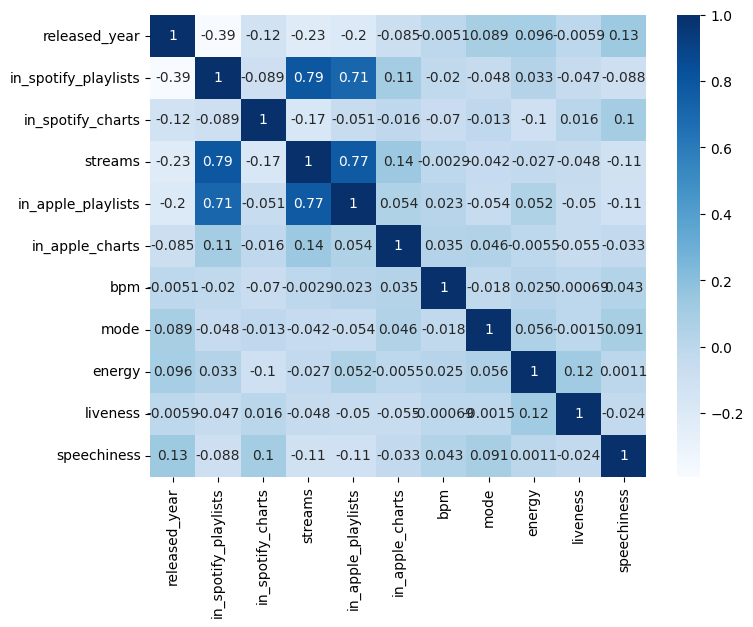

In [11]:
# Visualizing correlations among the remaining features.
import seaborn as sb

plt.figure(figsize=(8,6))
sb.heatmap(cl_data.corr(), cmap="Blues",annot=True)
plt.show()

In [12]:
# Streams, Apple playlist counts, and Spotify playlist counts are strongly correlated. To reduce redundancy in clustering, we are removing streams and Apple playlist counts, retaining Spotify playlist counts for now.

cl_data.drop(columns = ["in_apple_playlists", "streams"], inplace = True)

In [13]:

cl_data

,released_year,in_spotify_playlists,in_spotify_charts,in_apple_charts,bpm,mode,energy,liveness,speechiness
0,2023,553,147.0,263.0,125,0,83,8,4
1,2023,1474,48.0,126.0,92,0,74,10,4
2,2023,1397,113.0,207.0,138,0,53,31,6
3,2019,7858,3.0,207.0,170,0,72,11,15
4,2023,3133,50.0,133.0,144,1,80,11,6
...,...,...,...,...,...,...,...,...,...
948,2022,953,147.0,13.0,144,0,39,8,3
949,2022,1180,147.0,275.0,166,0,24,12,6
950,2022,573,147.0,275.0,92,0,67,8,6
951,2022,1320,147.0,26.0,97,0,77,12,5


#5. Outlier Analysis

Inspecting each feature for outliers because extreme values can affect clustering. Features with a large proportion of outliers (more than 10%) are removed; otherwise, winsorization is considered.

In [14]:
# Defining a helper function for displaying boxplots.

def draw_boxplot(values, label):
    plt.boxplot(values)
    plt.xlabel(label)
    plt.show()

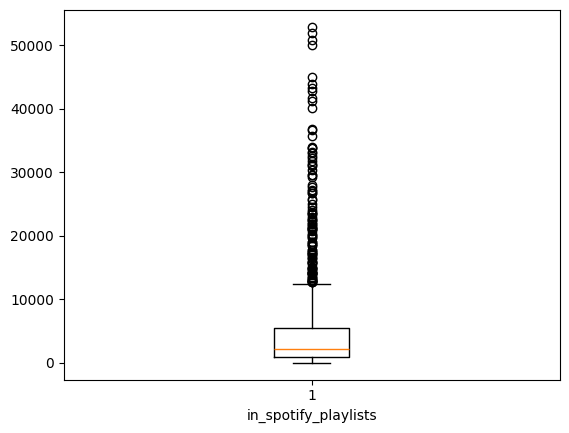

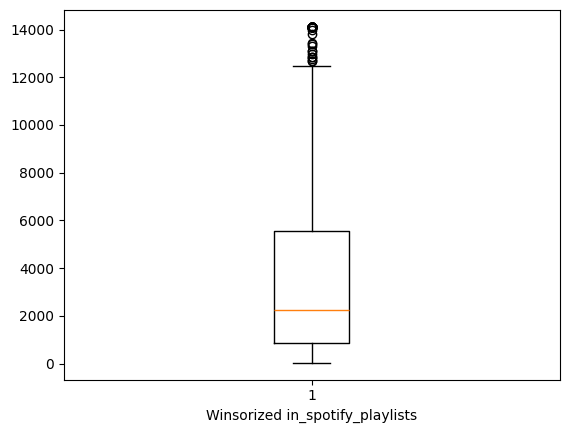

In [15]:
# Inspecting outliers in Spotify playlist counts.
from scipy.stats.mstats import winsorize

draw_boxplot(cl_data["in_spotify_playlists"], "in_spotify_playlists")
winsorized_data = winsorize(cl_data["in_spotify_playlists"], limits=[0.00, 0.10])
draw_boxplot(winsorized_data, "Winsorized in_spotify_playlists")
plt.show()

# Upper-tail winsorization at 10% does not eliminate all outliers in the original analysis, so this feature is removed.
cl_data.drop(columns = ["in_spotify_playlists"], inplace = True)

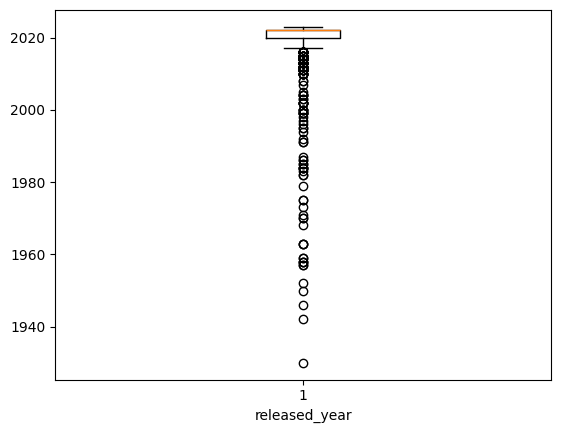

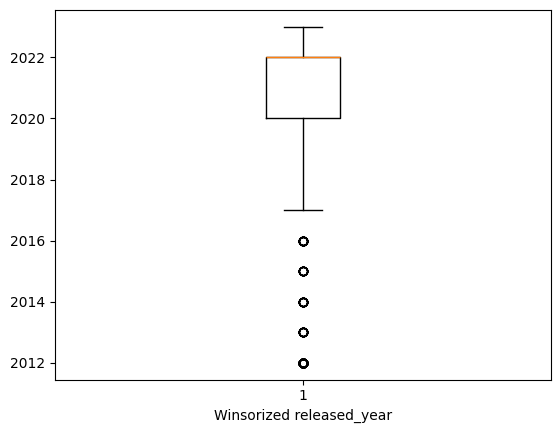

In [16]:
# Inspecting release-year outliers.

draw_boxplot(cl_data["released_year"], "released_year")
winsorized_data = winsorize(cl_data["released_year"], limits=[0.10, 0.00])
draw_boxplot(winsorized_data, "Winsorized released_year")

#  Lower-tail winsorization at 10% does not eliminate all outliers in the original analysis, so release_year is removed.
cl_data.drop(columns = ["released_year"], inplace = True)

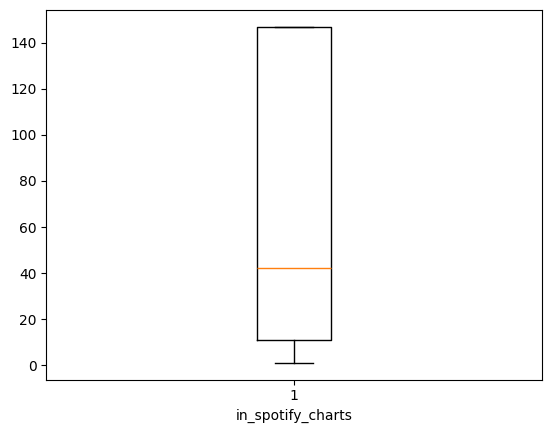

In [17]:
# Inspecting Spotify chart positions.

draw_boxplot(cl_data["in_spotify_charts"], "in_spotify_charts")

# The original analysis identifies no outliers requiring changes.

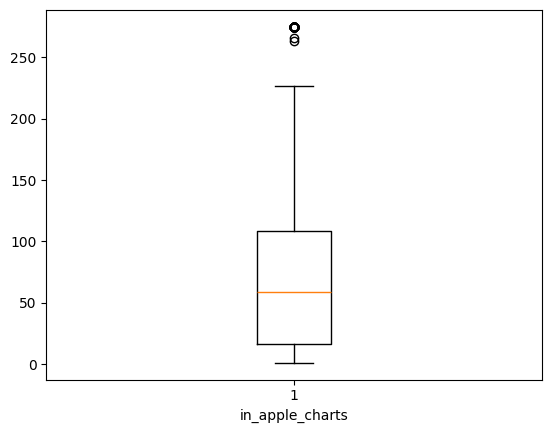

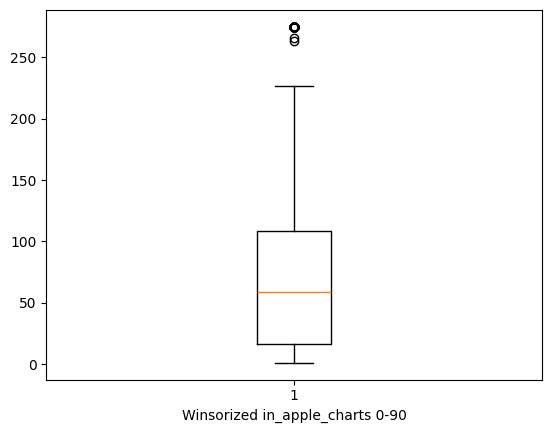

In [18]:
# Inspecting Apple chart positions.

draw_boxplot(cl_data["in_apple_charts"], "in_apple_charts")

winsorized_data = winsorize(cl_data["in_apple_charts"], limits=[0.00, 0.10])
draw_boxplot(winsorized_data, "Winsorized in_apple_charts 0-90")

#  Upper-tail winsorization at 10% does not eliminate all outliers in the original analysis, so this feature is removed.
cl_data.drop(columns = ["in_apple_charts"], inplace = True)

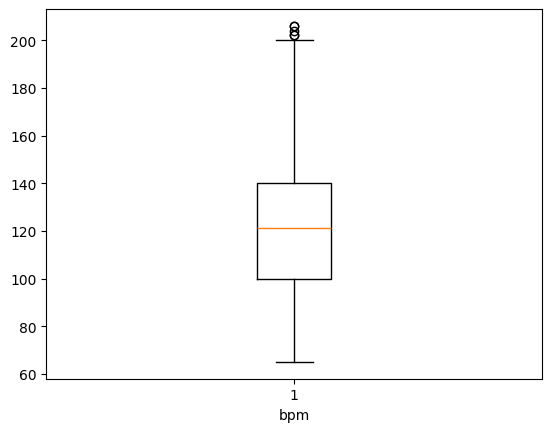

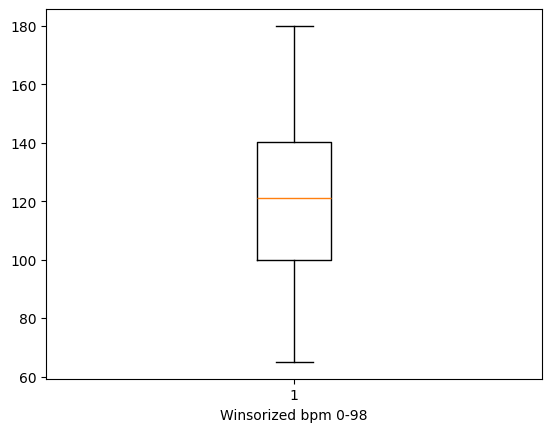

In [19]:
# Inspecting BPM.

draw_boxplot(cl_data["bpm"], "bpm")

winsorized_data = winsorize(cl_data["bpm"], limits=[0.00, 0.02])
draw_boxplot(winsorized_data, "Winsorized bpm 0-98")

# Upper-tail winsorization at 2% is used to limit the influence of extreme values, and the transformed values replace the original column.
cl_data["bpm"] = winsorized_data

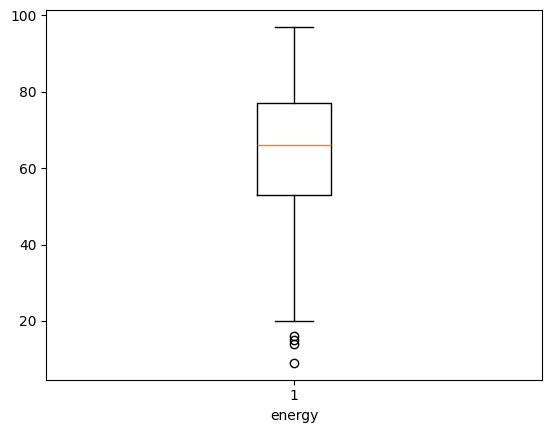

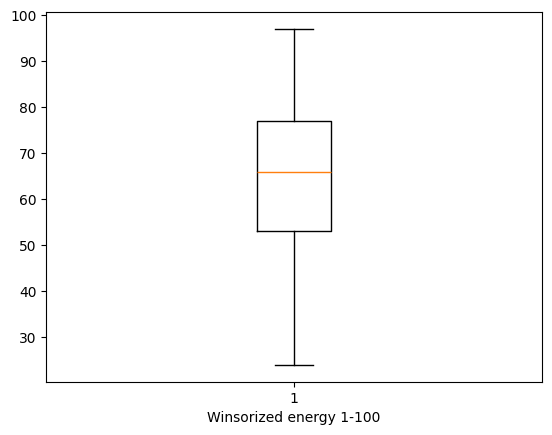

In [20]:
# Inspecting energy.
draw_boxplot(cl_data["energy"], "energy")

winsorized_data = winsorize(cl_data["energy"], limits=[0.01, 0.00])
draw_boxplot(winsorized_data, "Winsorized energy 1-100")

# Lower-tail winsorization at 1% is applied, and the transformed values replace the original column.
cl_data["energy"] = winsorized_data

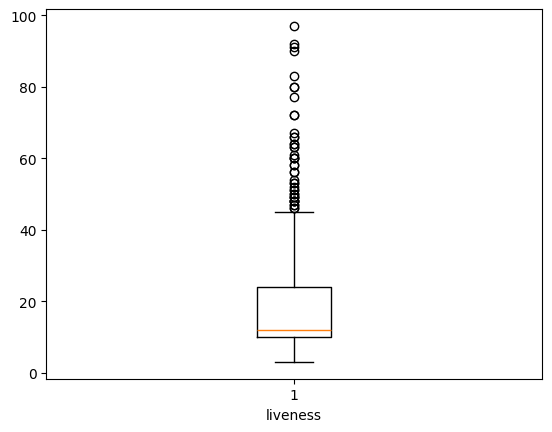

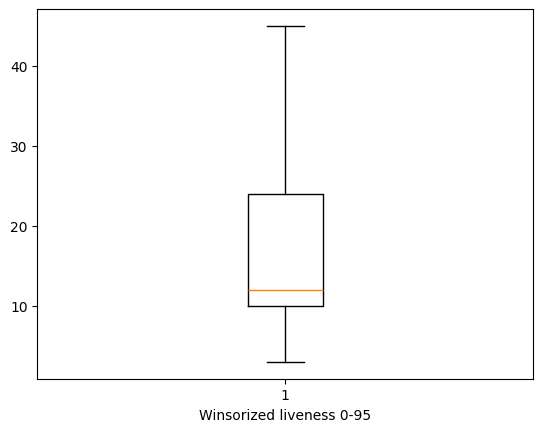

In [21]:
# Inspecting liveness.

draw_boxplot(cl_data["liveness"], "liveness")

winsorized_data = winsorize(cl_data["liveness"], limits=[0.00, 0.05])
draw_boxplot(winsorized_data, "Winsorized liveness 0-95")

# Upper-tail winsorization at 5% is applied, and the transformed values replace the original column.
cl_data["liveness"] = winsorized_data

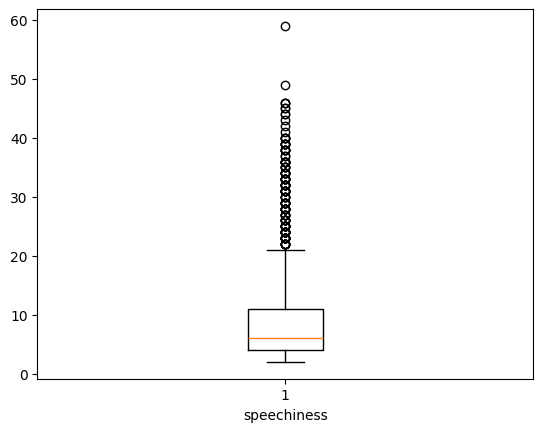

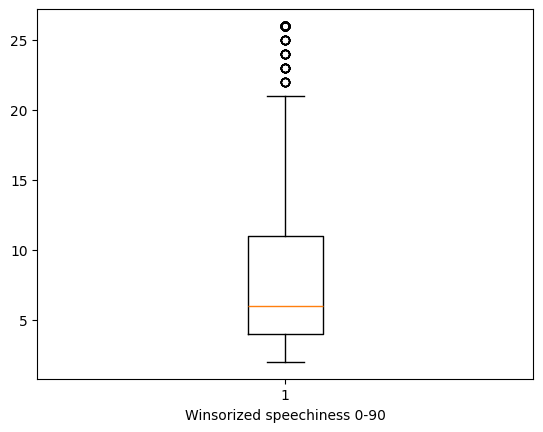

In [22]:
# Inspecting speechiness.

draw_boxplot(cl_data["speechiness"], "speechiness")

winsorized_data = winsorize(cl_data["speechiness"], limits=[0.00, 0.10])
draw_boxplot(winsorized_data, "Winsorized speechiness 0-90")

# Upper-tail winsorization at 10% does not eliminate all outliers in the original analysis, so this feature is removed.
cl_data.drop(columns = ["speechiness"], inplace = True)

In [23]:
# Inspecting the cleaned dataset after missing-value handling, correlation screening, and outlier treatment. Five features remain for clustering.

cl_data.describe()


,in_spotify_charts,bpm,mode,energy,liveness
count,952.000000,952.000000,952.000000,952.000000,952.000000
mean,74.398109,122.316176,0.422269,64.359244,17.460084
std,64.622987,27.490861,0.494181,16.380695,11.231925
min,1.000000,65.000000,0.000000,24.000000,3.000000
25%,11.000000,99.750000,0.000000,53.000000,10.000000
50%,42.000000,121.000000,0.000000,66.000000,12.000000
75%,147.000000,140.250000,1.000000,77.000000,24.000000
max,147.000000,180.000000,1.000000,97.000000,45.000000


#6. Feature Scaling (Normalization)

In [24]:
# Normalizing features to the [0, 1] interval using MinMaxScaler because their original scales differ substantially. Converting the resulting NumPy array back into a DataFrame and check the ranges.
from sklearn.preprocessing import MinMaxScaler
temp_data = MinMaxScaler().fit_transform(cl_data)
cl_data_scaled = pd.DataFrame(temp_data, columns = cl_data.columns)

cl_data_scaled.describe()

,in_spotify_charts,bpm,mode,energy,liveness
count,952.000000,952.000000,952.000000,952.000000,952.000000
mean,0.502727,0.498402,0.422269,0.552866,0.344288
std,0.442623,0.239051,0.494181,0.224393,0.267427
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.068493,0.302174,0.000000,0.397260,0.166667
50%,0.280822,0.486957,0.000000,0.575342,0.214286
75%,1.000000,0.654348,1.000000,0.726027,0.500000
max,1.000000,1.000000,1.000000,1.000000,1.000000


#7. Choosing the Number of Clusters and Linkage Method Using Dendrograms

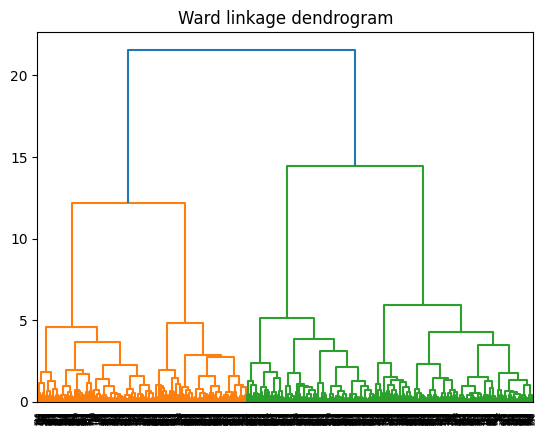

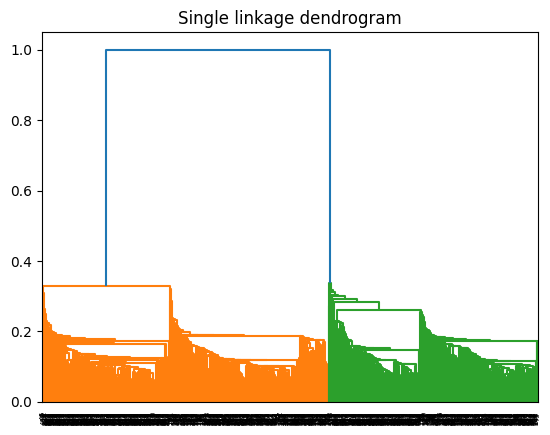

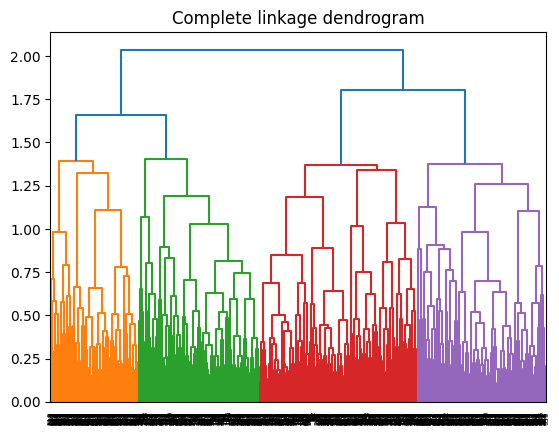

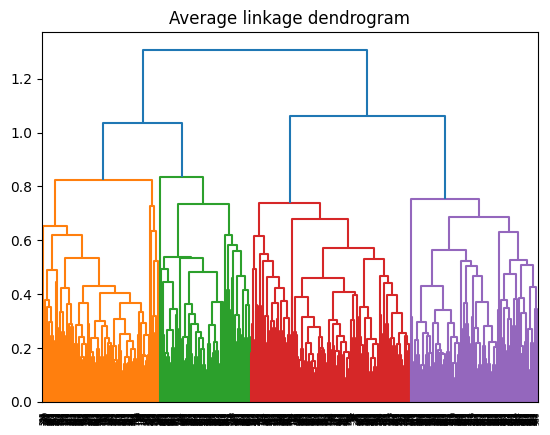

In [25]:
# Comparing dendrograms for Ward, single, complete, and average linkage using Euclidean distance.
from scipy.cluster.hierarchy import linkage, dendrogram

dendrogram(linkage(cl_data_scaled, method='ward', metric='euclidean'))
plt.title("Ward linkage dendrogram")
plt.show()

dendrogram(linkage(cl_data_scaled, method='single', metric='euclidean'))
plt.title("Single linkage dendrogram")
plt.show()

dendrogram(linkage(cl_data_scaled, method='complete', metric='euclidean'))
plt.title("Complete linkage dendrogram")
plt.show()

dendrogram(linkage(cl_data_scaled, method='average', metric='euclidean'))
plt.title("Average linkage dendrogram")
plt.show()



Complete and Average linkage suggest four relatively close clusters, while Single and Ward show two clearer groups. Ward also permits a four-cluster split, so both K = 2 and K = 4 are explored.

#8. Fitting Hierarchical Clustering with K=2

In [26]:
# Fitting agglomerative hierarchical clustering with Ward linkage, Euclidean distance, and two clusters.

h_cluster = cluster.AgglomerativeClustering(n_clusters=2, linkage = "ward", metric="euclidean").fit(cl_data_scaled)
cl_data_scaled["cluster"] = h_cluster.labels_

In [27]:
cl_data_scaled

,in_spotify_charts,bpm,mode,energy,liveness,cluster
0,1.000000,0.521739,0.0,0.808219,0.119048,0
1,0.321918,0.234783,0.0,0.684932,0.166667,0
2,0.767123,0.634783,0.0,0.397260,0.666667,0
3,0.013699,0.913043,0.0,0.657534,0.190476,0
4,0.335616,0.686957,1.0,0.767123,0.190476,1
...,...,...,...,...,...,...
947,1.000000,0.686957,0.0,0.205479,0.119048,0
948,1.000000,0.878261,0.0,0.000000,0.214286,0
949,1.000000,0.234783,0.0,0.589041,0.119048,0
950,1.000000,0.278261,0.0,0.726027,0.214286,0


#9. Interpreting the Clusters: Sizes, Feature Profiles, and Dispersion

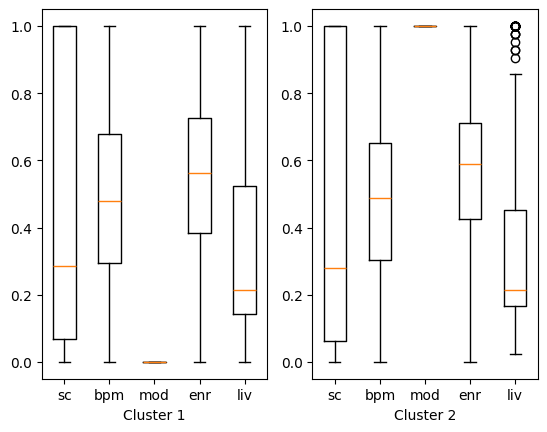

Cluster 1, N =  550
Cluster 2, N =  402


In [29]:
# Comparing the two hierarchical clusters with boxplots and print their sizes.

fig, ax = plt.subplots(1,2)

ax[0].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==0].drop(columns = ["cluster"]), tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[0].set_xlabel("Cluster 1")

ax[1].boxplot(cl_data_scaled[cl_data_scaled["cluster"]==1].drop(columns = ["cluster"]), tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[1].set_xlabel("Cluster 2")

plt.show()

print("Cluster 1, N = ", cl_data_scaled.loc[cl_data_scaled["cluster"]==0, "cluster"].count())
print("Cluster 2, N = ", cl_data_scaled.loc[cl_data_scaled["cluster"]==1, "cluster"].count())

Interpretation of the two-cluster solution:
 1. **Cluster sizes**: Cluster 1 contains 550 songs and Cluster 2 contains 402; both groups are of comparable size.
 2. **Cluster profiles**: Cluster 2 contains Minor-mode songs (mode = 1), while Cluster 1 contains Major-mode songs (mode = 0). Energy is slightly lower in Cluster 1. The other feature profiles are nearly identical, raising questions about how informative this split is.
 3. **Dispersion**: Both clusters have similar overall variability. Cluster 2 is somewhat more homogeneous for energy and liveness, but dispersion remains high, motivating a four-cluster alternative.

#10. Repeating Clustering with K = 4

In [33]:
# Remove existing cluster labels so they do not affect the new clustering. Fitting Ward-linkage hierarchical clustering with Euclidean distance and four clusters.

X = cl_data_scaled.drop(columns="cluster", errors="ignore")
h_cluster_4 = cluster.AgglomerativeClustering(n_clusters=4, linkage = "ward", metric="euclidean")
labels_4 = h_cluster_4.fit_predict(X)

cl_data_4 = X.copy()
cl_data_4["cluster"] = labels_4

print(cl_data_4["cluster"].value_counts().sort_index())
print("Total songs:", len(cl_data_4))

cluster
0    304
1    175
2    246
3    227
Name: count, dtype: int64
Total songs: 952


In [34]:
cl_data_4

,in_spotify_charts,bpm,mode,energy,liveness,cluster
0,1.000000,0.521739,0.0,0.808219,0.119048,2
1,0.321918,0.234783,0.0,0.684932,0.166667,0
2,0.767123,0.634783,0.0,0.397260,0.666667,2
3,0.013699,0.913043,0.0,0.657534,0.190476,0
4,0.335616,0.686957,1.0,0.767123,0.190476,3
...,...,...,...,...,...,...
947,1.000000,0.686957,0.0,0.205479,0.119048,2
948,1.000000,0.878261,0.0,0.000000,0.214286,2
949,1.000000,0.234783,0.0,0.589041,0.119048,2
950,1.000000,0.278261,0.0,0.726027,0.214286,2


#11. Interpreting the Four-Cluster Solution

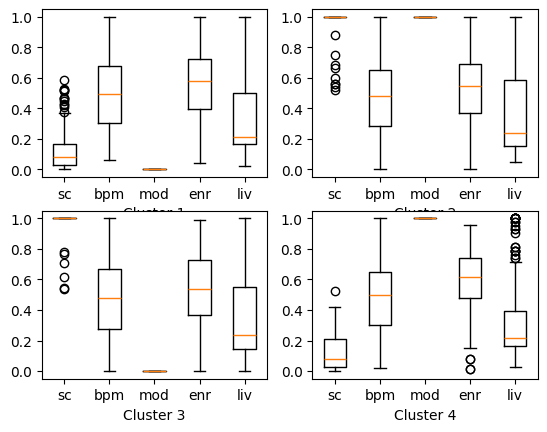

Cluster 1, N =  304
Cluster 2, N =  175
Cluster 3, N =  246
Cluster 4, N =  227


In [35]:
# Comparing the four hierarchical clusters.

fig, ax = plt.subplots(2, 2)

ax[0, 0].boxplot(cl_data_4[cl_data_4["cluster"] == 0].drop(columns=['cluster']),
                 tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[0, 0].set_xlabel("Cluster 1")

ax[0, 1].boxplot(cl_data_4[cl_data_4["cluster"] == 1].drop(columns=['cluster']),
                 tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[0, 1].set_xlabel("Cluster 2")

ax[1, 0].boxplot(cl_data_4[cl_data_4["cluster"] == 2].drop(columns=['cluster']),
                 tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[1, 0].set_xlabel("Cluster 3")

ax[1, 1].boxplot(cl_data_4[cl_data_4["cluster"] == 3].drop(columns=['cluster']),
                 tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[1, 1].set_xlabel("Cluster 4")

plt.show()

print("Cluster 1, N = ", cl_data_4.loc[cl_data_4["cluster"] == 0, "cluster"].count())
print("Cluster 2, N = ", cl_data_4.loc[cl_data_4["cluster"] == 1, "cluster"].count())
print("Cluster 3, N = ", cl_data_4.loc[cl_data_4["cluster"] == 2, "cluster"].count())
print("Cluster 4, N = ", cl_data_4.loc[cl_data_4["cluster"] == 3, "cluster"].count())

Interpretation of the four-cluster solution:
 1. **Cluster sizes**: Clusters 1–4 contain 304, 175, 246, and 227 songs, respectively; all groups are substantial.
 2. **Cluster profiles**: Cluster 2 contains lower-ranked Minor-mode songs, and Cluster 3 contains lower-ranked Major-mode songs. Cluster 1 contains better-ranked Major-mode songs, while Cluster 4 contains better-ranked Minor-mode songs. The better-ranked groups (1 and 4) also have slightly higher energy.
 3. **Dispersion**: Clusters 2 and 3 are highly homogeneous in Spotify chart positions because they consist of lower-ranked songs. Clusters 1 and 4 include the other ranked songs and therefore have greater variability in chart positions. Cluster 4 is comparatively more homogeneous for energy and liveness; differences in other features are limited.

## Conclusion

Hierarchical clustering was used to group Spotify songs based on their similarities.

After data preprocessing, feature selection, outlier treatment, and normalization, dendrograms were used to explore the relationships between songs and select the clustering parameters.

Two clustering solutions were analyzed, with K = 2 and K = 4 clusters. The resulting groups were compared based on their sizes, feature distributions, and variability.

The analysis demonstrates how hierarchical clustering can identify patterns and similarities in music data without using predefined class labels. It also shows how dendrograms help visualize relationships between observations and support the selection of the number of clusters.